# BM25F Expert Search — Aggregation Evaluation

**Experiment:** standard CombSUM vs discounted CombSUM on the same Whoosh BM25F retrieval results.

This notebook uses `metrics.csv`, `comparison.csv`, `expected_expert_ranks.csv`, and `rankings.csv` from `evaluate_bm25.py`. All charts use actual CSV data, not illustrative values. Metrics use **incomplete known-positive labels** (`expected_experts`), so they are *provisional* and should not be described as exhaustive relevance judgments.

Run **Kernel → Restart & Run All**. Charts can be saved to `bm25_results/plots/`.

In [5]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Works when notebook is in testing/, in testing/bm25_results/, or alongside the CSV files.
candidates = [Path('bm25_results'), Path('.'), Path('../bm25_results'), Path('testing/bm25_results')]
DATA_DIR = next((p for p in candidates if all((p / f).exists() for f in ['metrics.csv', 'comparison.csv', 'expected_expert_ranks.csv', 'rankings.csv'])), None)
if DATA_DIR is None:
    raise FileNotFoundError('Cannot locate results. Set DATA_DIR = Path("/path/to/testing/bm25_results")')
PLOT_DIR = DATA_DIR / 'plots'
PLOT_DIR.mkdir(parents=True, exist_ok=True)
SAVE_PLOTS = True
metrics = pd.read_csv(DATA_DIR / 'metrics.csv')
comparison = pd.read_csv(DATA_DIR / 'comparison.csv')
expected = pd.read_csv(DATA_DIR / 'expected_expert_ranks.csv')
rankings = pd.read_csv(DATA_DIR / 'rankings.csv')
METHODS = ['combsum', 'discounted']
LABELS = {'combsum':'CombSUM', 'discounted':'Discounted CombSUM'}
print('Data directory:', DATA_DIR.resolve())
print('Queries:', metrics.query_id.nunique(), '| Expected-expert instances:', len(expected))
print('Methods:', metrics.method.unique().tolist())
assert set(METHODS).issubset(set(metrics.method)), 'Missing one of the two methods'
assert metrics.groupby('query_id').method.nunique().eq(2).all(), 'Each query should have both methods'

def finish(fig, filename):
    fig.tight_layout()
    if SAVE_PLOTS:
        fig.savefig(PLOT_DIR / filename, dpi=180, bbox_inches='tight')
    plt.show()


Data directory: /Users/izahetmanowska/Desktop/ExpertsSearchEngine/testing/bm25_results
Queries: 452 | Expected-expert instances: 586
Methods: ['combsum', 'discounted']


## 1. Overall retrieval metrics

Recall@10, MRR@10, and nDCG@10 are based on *known expected experts*, not complete relevance labels.

,known_recall_at_k,known_mrr_at_k,known_ndcg_at_k
method,,,
CombSUM,0.4197,0.2318,0.2676
Discounted CombSUM,0.4438,0.2790,0.3060


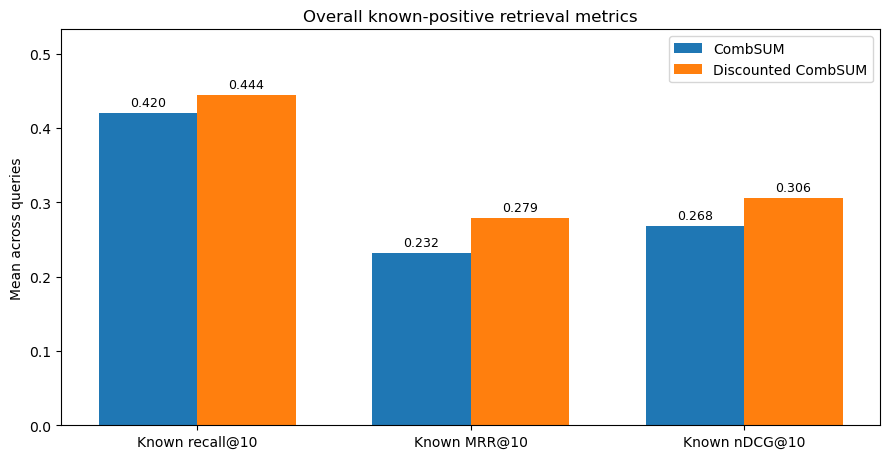

In [6]:
cols = ['known_recall_at_k','known_mrr_at_k','known_ndcg_at_k']
summary = metrics.groupby('method')[cols].mean().reindex(METHODS)
display(summary.rename(index=LABELS).round(4))
fig, ax = plt.subplots(figsize=(9, 4.7))
x = np.arange(len(cols)); w = .36
for i, method in enumerate(METHODS):
    bars = ax.bar(x + (i-.5)*w, summary.loc[method].to_numpy(), w, label=LABELS[method])
    ax.bar_label(bars, fmt='%.3f', padding=3, fontsize=9)
ax.set_xticks(x, ['Known recall@10','Known MRR@10','Known nDCG@10'])
ax.set_ylim(0, max(.5, summary.to_numpy().max()*1.2))
ax.set_ylabel('Mean across queries'); ax.set_title('Overall known-positive retrieval metrics')
ax.legend(); finish(fig, '01_overall_metrics.png')

## 2. Academic vs student-style queries

method,combsum,discounted
query_type,,
academic,0.3349,0.3762
student_style,0.2003,0.2359


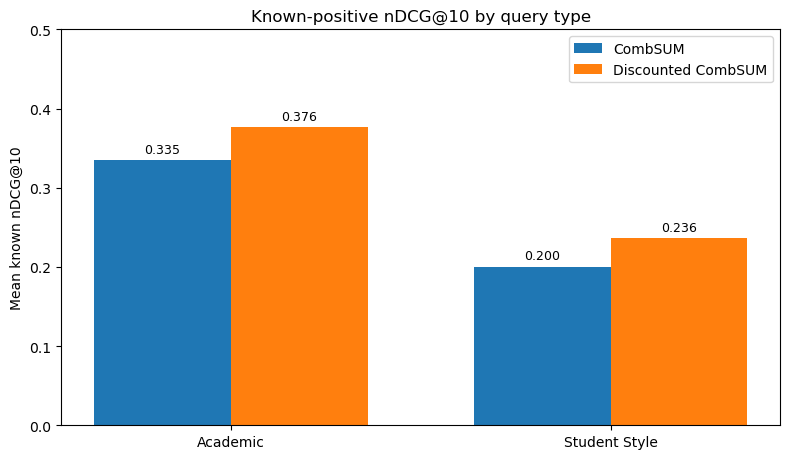

In [7]:
by_type = metrics.groupby(['query_type','method'])['known_ndcg_at_k'].mean().unstack().reindex(columns=METHODS)
display(by_type.round(4))
fig, ax = plt.subplots(figsize=(8, 4.7))
x = np.arange(len(by_type)); w = .36
for i, method in enumerate(METHODS):
    bars = ax.bar(x + (i-.5)*w, by_type[method], w, label=LABELS[method])
    ax.bar_label(bars, fmt='%.3f', padding=3, fontsize=9)
ax.set_xticks(x, [s.replace('_',' ').title() for s in by_type.index]); ax.set_ylabel('Mean known nDCG@10')
ax.set_ylim(0, max(.5, by_type.to_numpy().max()*1.2)); ax.set_title('Known-positive nDCG@10 by query type')
ax.legend(); finish(fig, '02_ndcg_by_query_type.png')

## 3. Top-10 ranking overlap

Overlap is the number of researchers appearing in both top-10 lists for the same query. This measures **ranking stability**, not relevance.

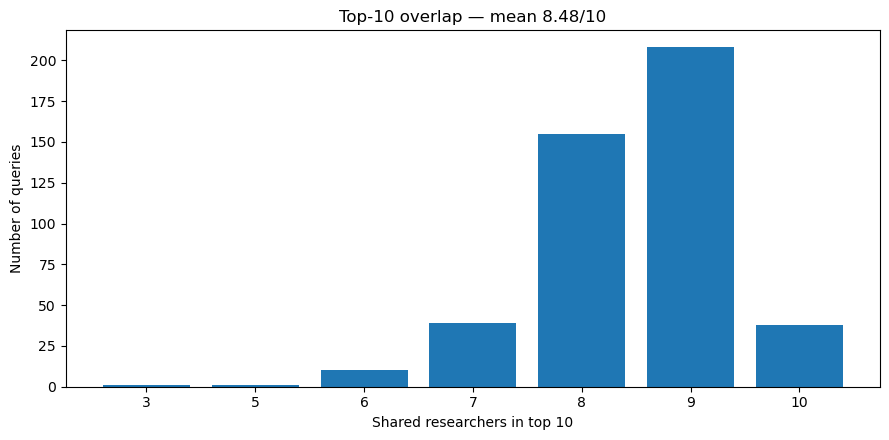

Same top-ranked researcher: 63.9%


In [8]:
counts = comparison.top_k_overlap_count.value_counts().sort_index()
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.bar(counts.index.astype(str), counts.values)
ax.set_xlabel('Shared researchers in top 10'); ax.set_ylabel('Number of queries')
ax.set_title(f'Top-10 overlap — mean {comparison.top_k_overlap_count.mean():.2f}/10')
finish(fig, '03_top10_overlap.png')
print('Same top-ranked researcher: {:.1%}'.format(comparison.same_first_result.mean()))

## 4. Did the expected expert move up or down?

We distinguish experts found by both methods from experts entering or leaving the top 10. `not_in_top_k` does **not** mean the researcher was absent from the entire index or retrieval pool.

,Expected-expert instances
outcome,
Found by both,218
Discounted only,24
CombSUM only,6
Neither in top 10,338


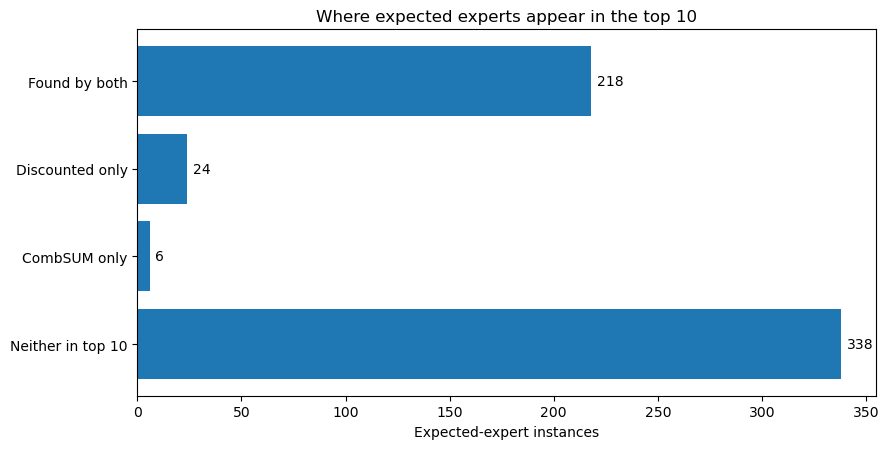

In [9]:
for c in ['combsum_found','discounted_found']:
    expected[c] = pd.to_numeric(expected[c], errors='coerce').fillna(0).astype(int)
conditions = [
    (expected.combsum_found.eq(1) & expected.discounted_found.eq(1)),
    (expected.combsum_found.eq(1) & expected.discounted_found.eq(0)),
    (expected.combsum_found.eq(0) & expected.discounted_found.eq(1))]
choices = ['Found by both','CombSUM only','Discounted only']
expected['outcome'] = np.select(conditions, choices, default='Neither in top 10')
order = ['Found by both','Discounted only','CombSUM only','Neither in top 10']
ct = expected.outcome.value_counts().reindex(order, fill_value=0)
display(ct.rename('Expected-expert instances').to_frame())
fig, ax = plt.subplots(figsize=(9, 4.6))
bars = ax.barh(ct.index[::-1], ct.values[::-1]); ax.bar_label(bars, padding=4)
ax.set_xlabel('Expected-expert instances'); ax.set_title('Where expected experts appear in the top 10')
finish(fig, '04_expected_expert_outcomes.png')

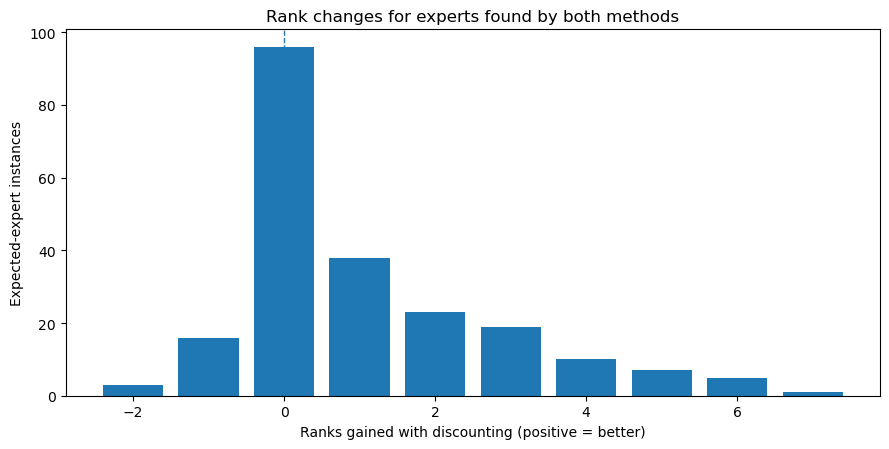

Mean ranks gained (found by both): 1.06


In [10]:
both = expected.loc[expected.outcome.eq('Found by both')].copy()
both['baseline_rank'] = pd.to_numeric(both.combsum_rank, errors='coerce')
both['discounted_rank_num'] = pd.to_numeric(both.discounted_rank, errors='coerce')
both['improvement'] = both.baseline_rank - both.discounted_rank_num
improvements = both.improvement.value_counts().sort_index()
fig, ax = plt.subplots(figsize=(9, 4.6))
ax.bar(improvements.index, improvements.values)
ax.axvline(0, linestyle='--', linewidth=1)
ax.set_xlabel('Ranks gained with discounting (positive = better)')
ax.set_ylabel('Expected-expert instances'); ax.set_title('Rank changes for experts found by both methods')
finish(fig, '05_expected_expert_rank_changes.png')
print('Mean ranks gained (found by both):', round(both.improvement.mean(), 3))

## 5. How much do researcher scores decrease?

Compare the **same researcher for the same query** across methods. Scores are aggregation scores, not relevance judgments. Only researchers appearing in both exported top-10 lists can be paired here.

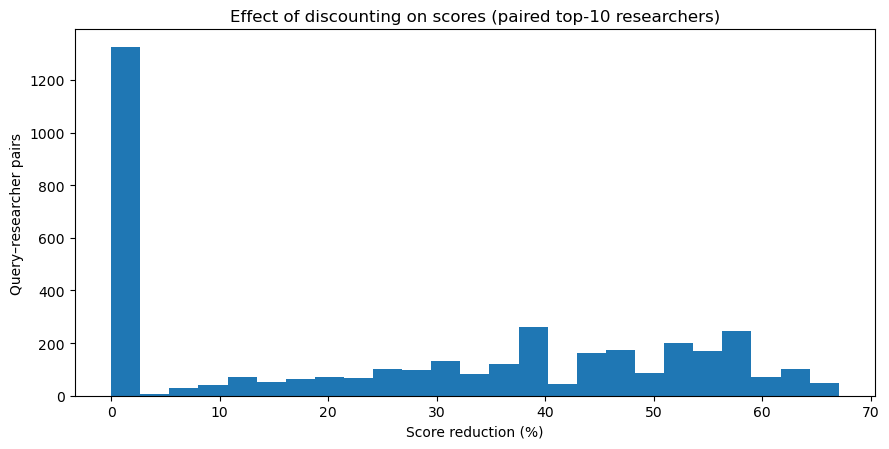

Paired researcher-query instances: 3833
Median score reduction: 29.0%


In [11]:
pair = rankings.pivot_table(index=['query_id','researcher_uuid'], columns='method', values='score', aggfunc='first')
pair = pair.dropna(subset=METHODS).copy()
pair['reduction_pct'] = np.where(pair.combsum > 0, 100*(pair.combsum-pair.discounted)/pair.combsum, np.nan)
fig, ax = plt.subplots(figsize=(9, 4.6))
ax.hist(pair.reduction_pct.dropna(), bins=25)
ax.set_xlabel('Score reduction (%)'); ax.set_ylabel('Query–researcher pairs')
ax.set_title('Effect of discounting on scores (paired top-10 researchers)')
finish(fig, '06_score_reductions.png')
print('Paired researcher-query instances:', len(pair))
print('Median score reduction: {:.1f}%'.format(pair.reduction_pct.median()))

## 6. Which queries benefit most?

These tables help identify examples to discuss in your thesis. A positive nDCG difference means the discounted method ranks the **known expected experts** more favorably.

In [12]:
wide = metrics.pivot(index='query_id', columns='method', values='known_ndcg_at_k')
wide['ndcg_gain'] = wide['discounted'] - wide['combsum']
query_info = metrics.drop_duplicates('query_id')[['query_id','query','query_type']].set_index('query_id')
changes = query_info.join(wide).sort_values('ndcg_gain', ascending=False)
print('Largest improvements:')
display(changes.head(10))
print('Largest declines:')
display(changes.tail(10).sort_values('ndcg_gain'))
print('Queries improved:', (changes.ndcg_gain > 0).sum(), '| worsened:', (changes.ndcg_gain < 0).sum(), '| unchanged:', (changes.ndcg_gain == 0).sum())

Largest improvements:


,query,query_type,combsum,discounted,ndcg_gain
query_id,,,,,
100,How could I use or study red teaming in a univ...,student_style,0.218407,0.797723,0.579315
105,Query optimisation and tech summit,academic,0.430677,1.000000,0.569323
441,Called deep and computer programs,academic,0.430677,1.000000,0.569323
24,Could we still pay for things if digital payme...,student_style,0.430677,1.000000,0.569323
442,How could I use or study called deep in a univ...,student_style,0.430677,1.000000,0.569323
163,Center computing and computing education,academic,0.500000,1.000000,0.500000
204,How could I use or study cellular automata in ...,student_style,0.500000,1.000000,0.500000
140,How could I use or study big things in a unive...,student_style,0.500000,1.000000,0.500000
82,How could I use or study cyber attacks in a un...,student_style,0.395647,0.806574,0.410927


Largest declines:


,query,query_type,combsum,discounted,ndcg_gain
query_id,,,,,
26,How can companies know if their security softw...,student_style,1.000000,0.63093,-0.369070
146,How could I use or study social networks in a ...,student_style,1.000000,0.63093,-0.369070
312,How could I use or study elections voting in a...,student_style,1.000000,0.63093,-0.369070
320,How could I use or study blockchain systems in...,student_style,1.000000,0.63093,-0.369070
323,Want change and used real,academic,1.000000,0.63093,-0.369070
17,digital welfare state,academic,1.000000,0.63093,-0.369070
18,How does digitalisation affect people using pu...,student_style,1.000000,0.63093,-0.369070
193,Young academy and networks data,academic,1.000000,0.63093,-0.369070
443,Best paper award and emotional state,academic,0.315465,0.00000,-0.315465


Queries improved: 116 | worsened: 23 | unchanged: 313


## 7. Optional: paired bootstrap uncertainty for nDCG@10

Resample **query strings** as clusters (rather than treating repeated strings as independent observations). This is an exploratory 95% bootstrap interval, not a replacement for complete relevance judgments.

Mean paired nDCG@10 difference: +0.0384
Cluster-bootstrap 95% interval: [+0.0261, +0.0509]


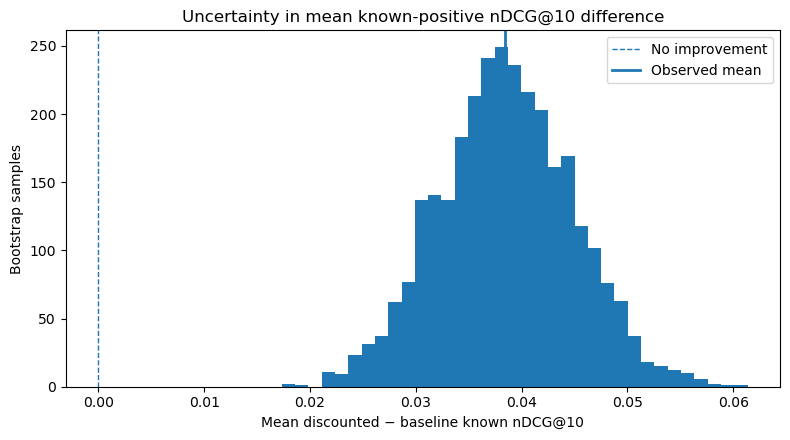

In [13]:
joined = changes.reset_index()
cluster_effect = joined.groupby('query')['ndcg_gain'].agg(['sum','count'])
rng = np.random.default_rng(42)
B = 3000
samples = rng.integers(0, len(cluster_effect), size=(B, len(cluster_effect)))
sums = cluster_effect['sum'].to_numpy(); counts = cluster_effect['count'].to_numpy()
boot = sums[samples].sum(axis=1) / counts[samples].sum(axis=1)
lo, hi = np.quantile(boot, [.025,.975])
print(f'Mean paired nDCG@10 difference: {joined.ndcg_gain.mean():+.4f}')
print(f'Cluster-bootstrap 95% interval: [{lo:+.4f}, {hi:+.4f}]')
fig, ax = plt.subplots(figsize=(8,4.5))
ax.hist(boot, bins=35)
ax.axvline(0, linestyle='--', linewidth=1, label='No improvement')
ax.axvline(joined.ndcg_gain.mean(), linewidth=2, label='Observed mean')
ax.set_xlabel('Mean discounted − baseline known nDCG@10'); ax.set_ylabel('Bootstrap samples')
ax.set_title('Uncertainty in mean known-positive nDCG@10 difference'); ax.legend()
finish(fig, '07_ndcg_bootstrap.png')

### Interpretation & Key Findings

The results suggest that **Discounted CombSUM improves expert ranking** compared to standard CombSUM, particularly by reducing the influence of repeated course offerings.

- **Overall performance improved:** nDCG@10 increased from 0.268 to 0.306 (+14.4%), while MRR@10 increased from 0.232 to 0.279 (+20.4%).
- **Ranking stability:** Both methods shared an average of 8.48 out of 10 researchers, suggesting that discounting mainly changes ranking positions rather than completely replacing the results.
- **Expected experts:** Discounted CombSUM retrieved 24 expected-expert instances missed by the baseline, while losing six.
- **Query types:** Academic queries performed better than student-style queries under both methods, suggesting limitations in lexical matching for natural-language questions.
- **Score distribution:** Researchers with repeated course offerings experienced the largest score reductions, while researchers with publications, projects, or distinct courses were less affected.
- **Uncertainty:** Bootstrap results suggest a consistently positive improvement, although related queries may affect statistical independence.

**Limitations:** The evaluation uses incomplete relevance judgments derived from ITU news articles. Therefore, improvements reflect better ranking of *known relevant experts*, not necessarily overall retrieval quality.

**Conclusion:** Discounted CombSUM appears to reduce the bias toward repeated course records while preserving teaching experience as evidence of expertise. However, 338 expected-expert instances remain outside the top 10 under both methods, indicating that document retrieval and researcher aggregation require further investigation.

**Next step:** Distinguish between document retrieval failures (expected experts have no documents in the top 100) and ranking failures (their documents are retrieved, but they do not reach the top 10).